In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib


Import Libraries

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/data set/SeoulBikeData.csv', encoding='latin1')

Loading Seoul Bike Data set

In [ ]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


This Seoul Bike dataset project focuses on analyzing bike rental demand using environmental and temporal factors. The dataset contains hourly records of bike rentals along with weather conditions, seasonal variations, and operational status.
**The dataset includes the following key features:**
Date & Hour → Time-based information for trend analysis
Rented Bike Count → Target variable (number of bikes rented)
**1. Weather Factors:**
Temperature (°C)
Humidity (%)
Wind Speed (m/s)
Visibility (10m)
Dew Point Temperature (°C)
Solar Radiation (MJ/m²)
Rainfall (mm)
Snowfall (cm)
**2. Categorical Features:**
Seasons (Winter, Summer, etc.)
Holiday (Yes/No)
Functioning Day (Operational status)

Information of Bike Dataset

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   object 
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   object 
 12  Holiday                    8760 non-null   object 
 13  Functioning Day            8760 non-null   objec

Number of Rows in data set

In [ ]:
df.index

RangeIndex(start=0, stop=8760, step=1)

In [ ]:
duplicate_value=df.duplicated().value_counts()
duplicate_value

,count
False,8760


Understanding your variables

In [ ]:
df.columns

Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day'],
      dtype='object')

Describe your dataset

In [ ]:
df.describe(include='all')

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
count,8760,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760,8760,8760
unique,365,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,2,2
top,30/11/2018,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Spring,No Holiday,Yes
freq,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2208,8328,8465
mean,NaN,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068,NaN,NaN,NaN
std,NaN,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746,NaN,NaN,NaN
min,NaN,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000,NaN,NaN,NaN
25%,NaN,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000,NaN,NaN,NaN
50%,NaN,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000,NaN,NaN,NaN
75%,NaN,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000,NaN,NaN,NaN


In [ ]:
df.shape

(8760, 14)

Missing Values in each columns

In [ ]:
df.isnull().sum()

,0
Date,0
Rented Bike Count,0
Hour,0
Temperature(°C),0
Humidity(%),0
Wind speed (m/s),0
Visibility (10m),0
Dew point temperature(°C),0
Solar Radiation (MJ/m2),0
Rainfall(mm),0


In [ ]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df['Day'] = df['Date'].dt.day
df['Month'] = df['Date'].dt.month
df['Year'] = df['Date'].dt.year

In [ ]:
df.columns

Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day', 'Day', 'Month', 'Year'],
      dtype='object')

In [ ]:
def temp_category(temp):
    if temp < 10:
        return 'Cold'
    elif temp < 25:
        return 'Moderate'
    else:
        return 'Hot'

df['Temp_Category'] = df['Temperature(°C)'].apply(temp_category)

In [ ]:
df.columns

Index(['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)',
       'Wind speed (m/s)', 'Visibility (10m)', 'Dew point temperature(°C)',
       'Solar Radiation (MJ/m2)', 'Rainfall(mm)', 'Snowfall (cm)', 'Seasons',
       'Holiday', 'Functioning Day', 'Day', 'Month', 'Year', 'Temp_Category'],
      dtype='object')

High Rentals demand when Temperature > 25°C which increase in bike rentals

In [ ]:
high_temp = df[df['Temperature(°C)'] > 25]

high_temp[['Temperature(°C)', 'Rented Bike Count']].head()

,Temperature(°C),Rented Bike Count
3374,25.9,970
3375,26.1,1080
3376,25.7,1206
3377,25.6,1543
3785,25.5,2392


In [ ]:
high_temp['Rented Bike Count'].mean()
df['Rented Bike Count'].mean()

np.float64(704.6020547945205)

Rental Drop During Rainfall & Snowfall When Rainfall > 0 which decrease in bike rentals

In [ ]:
rain = df[df['Rainfall(mm)'] > 0]
rain['Rented Bike Count'].mean()

np.float64(163.4564393939394)

When Snowfall > 0 Winter Season Shows Low Demand which lowest demand period

In [ ]:
snowy = df[df['Snowfall (cm)'] > 0]
snowy['Rented Bike Count'].mean()

np.float64(185.10158013544017)

In [ ]:
winter = df[df['Seasons'] == 'Winter']
other_seasons = df[df['Seasons'] != 'Winter']

winter['Rented Bike Count'].mean()
other_seasons['Rented Bike Count'].mean()

np.float64(861.385606060606)

In [ ]:
seasonal_data = df.groupby('Seasons')['Rented Bike Count'].mean()
print(seasonal_data)

Seasons
Autumn     819.597985
Spring     730.031250
Summer    1034.073370
Winter     225.541204
Name: Rented Bike Count, dtype: float64


In [ ]:
seasonal_data = df.groupby('Seasons')['Rented Bike Count'].mean()

print("Highest:", seasonal_data.idxmax())
print("Lowest:", seasonal_data.idxmin())

Highest: Summer
Lowest: Winter


Understand the relationships between variables through data visualization, storytelling, and chart experimentation

/tmp/ipykernel_8979/1615576422.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


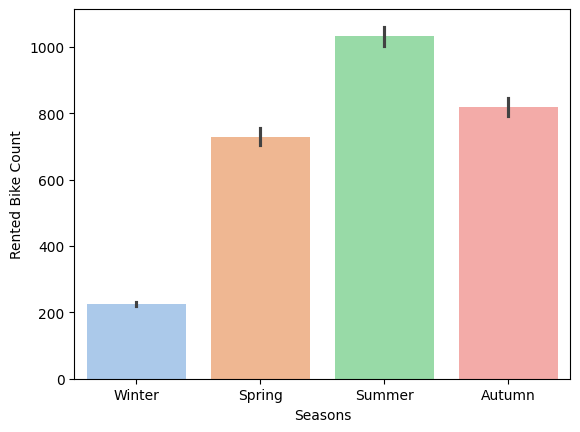

In [ ]:
#chart 1 -  Bar chart for seasonwise rented bike count
sns.barplot(
    x='Seasons',
    y='Rented Bike Count',
    data=df,
    estimator='mean',
    palette='pastel'
)
plt.show()

/tmp/ipykernel_8979/3231820774.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Month', y='Rented Bike Count', data=Month, palette='viridis')


<Axes: xlabel='Month', ylabel='Rented Bike Count'>

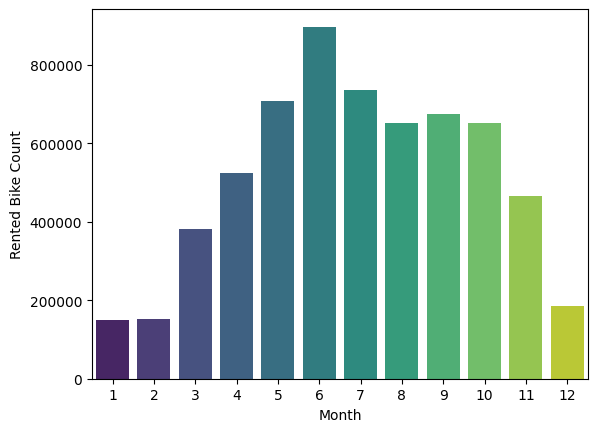

In [ ]:
Month = df.groupby('Month')['Rented Bike Count'].sum().reset_index()

sns.barplot(x='Month', y='Rented Bike Count', data=Month, palette='viridis')

In [ ]:
plt.figure(figsize=(10,6))
sns.barplot(x='Holiday', y='Rented Bike Count', data=df, palette='coolwarm')
plt.title('Bike Usage on Holidays vs Non-Holidays')

NameError: name 'plt' is not defined

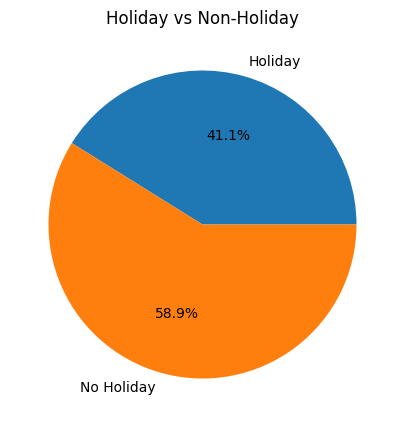

In [ ]:
df.groupby('Holiday')['Rented Bike Count'].mean().plot.pie(
    autopct='%1.1f%%',
    figsize=(5,5),
    title='Holiday vs Non-Holiday'
)

plt.ylabel('')
plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


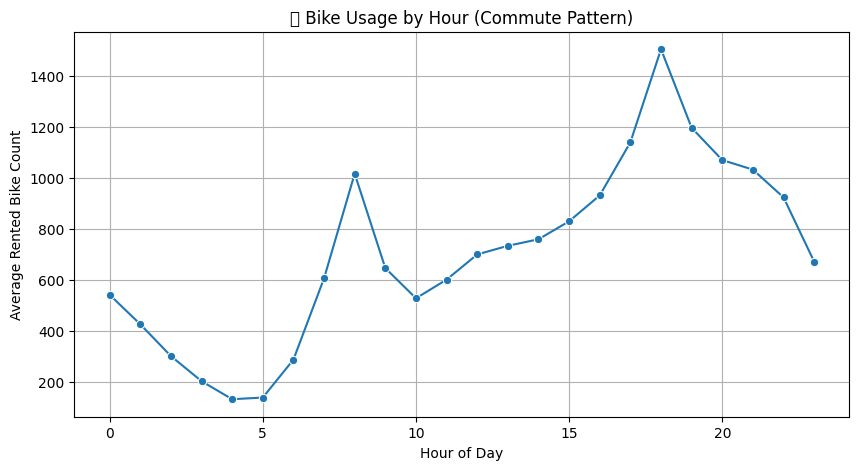

In [ ]:

# Group by hour
hour_df = df.groupby('Hour')['Rented Bike Count'].mean().reset_index()

plt.figure(figsize=(10,5))
sns.lineplot(x='Hour', y='Rented Bike Count', data=hour_df, marker='o')

plt.title('📈 Bike Usage by Hour (Commute Pattern)')
plt.xlabel('Hour of Day')
plt.ylabel('Average Rented Bike Count')

plt.grid(True)
plt.show()

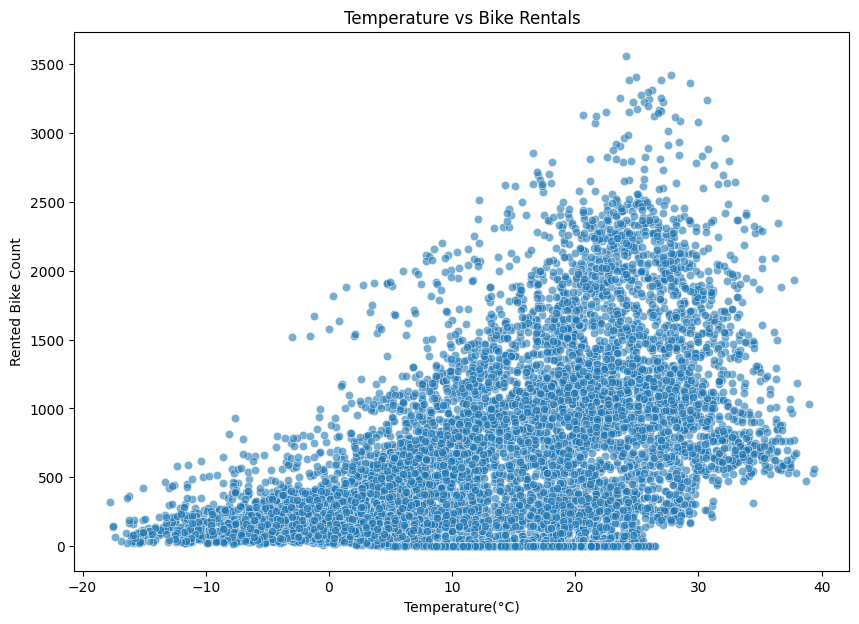

In [ ]:
plt.figure(figsize=(10,7))
sns.scatterplot(x='Temperature(°C)', y='Rented Bike Count', data=df, alpha=0.6)

plt.title('Temperature vs Bike Rentals')
plt.xlabel('Temperature(°C)')
plt.ylabel('Rented Bike Count')

plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


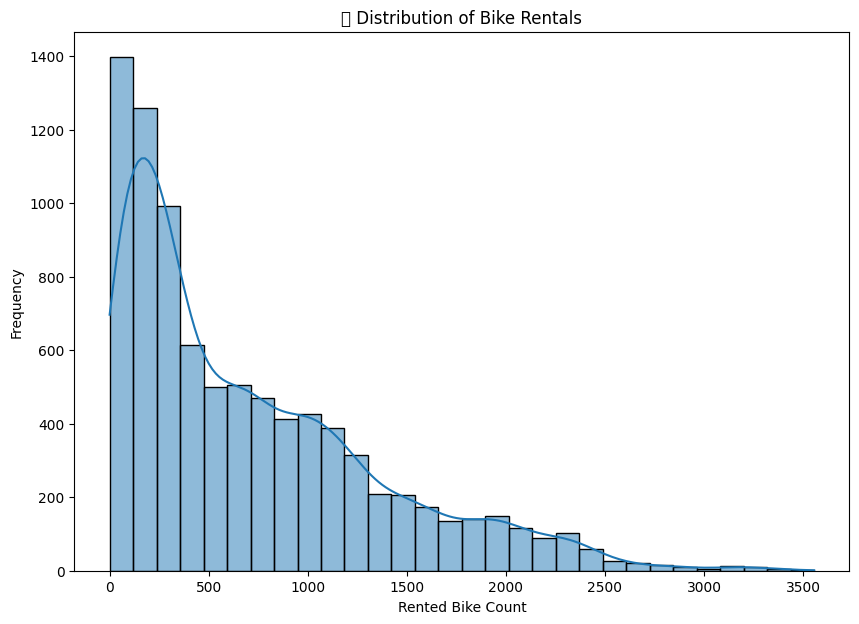

In [ ]:
plt.figure(figsize=(10,7))
sns.histplot(df['Rented Bike Count'], bins=30, kde=True)

plt.title('📊 Distribution of Bike Rentals')
plt.xlabel('Rented Bike Count')
plt.ylabel('Frequency')

plt.show()